# Final evaluation: how does the frozen configuration behave on never-used instances?

This notebook examines frozen outputs (`outputs/frozen/evaluation/`) to evaluate how the selected OR-Tools configuration (Perron & Furnon, 2026) performs on the 42 held-out evaluation instances excluded from tournament selection and budget tuning, without running any solver.

Following the pre-registered protocol (`reports/protocolo-avaliacao.md`; Nosek et al., 2018), the frozen configuration `fixed_cost` + `SAVINGS` (Clarke & Wright, 1964) + `GUIDED_LOCAL_SEARCH` (Voudouris & Tsang, 1999) ran unchanged for 120 s across 5 replicates per instance (210 OR-Tools runs plus 84 single runs from the two deterministic baselines, totalling 294 cells; Barr et al., 1995). The runtime budget moved from 30 s in the tournament to 120 s based on the development time curve (notebook 04, section 7), where mean Δ dropped from 1.00 (10 s) to 0.64 (120 s) before plateauing at 300 s.

The primary result uses the median replicate (3rd of 5 under lexicographic sorting by feasibility, vehicles and distance), reporting the best of 5 separately. Against SINTEF, Δ vehicles and distance gap occupy separate columns and the gap applies strictly under equal fleets, with no significance testing or optimality claims and no post-hoc parameter adjustments (Kaufman et al., 2012). Section 11 presents a post-hoc v2 re-evaluation side by side without replacing v1 (`reports/protocolo-fase-d.md`).

## 1. Environment setup

This stage loads the split, effective configuration (`config/experiment.toml`), frozen configuration and evaluation records, building the per-instance table (median replicate, best of 5 and spread). The table prints the effective protocol settings.

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import (
    benchmark,
    config,
    eda,
    evaluation,
    final_eval,
    paths,
    results,
    viz_final,
    viz_results,
)
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
cfg = config.load_config()
selected = results.load_selected_config(R["selected_config"], split)
rows = results.load_evaluation(R["evaluation"], split)
inst = evaluation.instance_table(rows)

display(eda.localize_columns(final_eval.protocol_table(cfg, selected, LANG), LANG))

,Indicator,Value
0,Fleet strategy (frozen),fixed_cost
1,First solution (frozen),SAVINGS
2,Metaheuristic (frozen),GUIDED_LOCAL_SEARCH
3,Tournament budget (s),30
4,Evaluation budget (s per run),120
5,Replicates per instance,5
6,Main result,median replicate (position 3 of 5)
7,Baselines (1 run per instance),yes
8,Instance set,eval


### Insight

Loaded settings match the pre-registered protocol: `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH`, 120 s per run, 5 replicates with the median replicate (rank 3 of 5) as main outcome, baselines included and `eval` split restriction. Exact correspondence with the archived run is guaranteed by the protocol and run metadata rather than runtime inspection here. Execution integrity is verified next.

## 2. Execution integrity

To confirm completeness and isolation on the evaluation set, the audit table counts total cells, method subsets, distinct instances, any stray development cases, double-precision feasibility, solver status and runtimes.

In [2]:
display(eda.localize_columns(final_eval.integrity_table(rows, split, LANG), LANG))

,Indicator,Value
0,Cells in the file (total),294
1,OR-Tools cells (instances × replicates),210
2,Baseline cells,84
3,Distinct instances,42
4,Evaluation instances in the split,42
5,Development instances in the results,0
6,OR-Tools replicates per instance,5
7,Cells feasible in the verifier,294 / 294
8,OR-Tools runs with success status,210 / 210
9,Mean time per OR-Tools run (s),120.0


### Insight

The frozen file holds 294 cells, combining 210 OR-Tools runs (42 instances times 5 replicates) and 84 baseline runs (2 times 42) strictly across the 42 evaluation instances with zero development leaks. Every cell passes the double-precision verifier and all 210 OR-Tools solves exited with success status, consuming the full 120.0 s budget (120.00 to 120.04 s). With integrity confirmed, section 3 measures quality against SINTEF.

## 3. Main result against SINTEF

The tables report performance relative to SINTEF (SINTEF, 2008) overall and per family, listing instance counts, mean Δ vehicles, equal-fleet matches, median equal-fleet distance gap and instances beating the reference hierarchically (Bräysy & Gendreau, 2005a). The first table gives the main result (median replicate), while the second lists the best of 5 replicates for context.

In [3]:
display(eda.localize_columns(final_eval.main_table(rows, LANG), LANG))
display(eda.localize_columns(final_eval.main_table(rows, LANG, best=True), LANG))

,Result,Scope,No. of instances,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Beats the reference
0,Median replicate (main result),Overall,42,0.50,24,3.4,0
1,Median replicate (main result),C1,7,0.00,7,0.0,0
2,Median replicate (main result),C2,6,0.00,6,0.0,0
3,Median replicate (main result),R1,9,0.89,1,0.52,0
4,Median replicate (main result),R2,8,0.25,6,5.02,0
5,Median replicate (main result),RC1,6,1.50,0,-,0
6,Median replicate (main result),RC2,6,0.33,4,4.63,0


,Result,Scope,No. of instances,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Beats the reference
0,Best of 5 (separate),Overall,42,0.50,24,2.65,0
1,Best of 5 (separate),C1,7,0.00,7,0.0,0
2,Best of 5 (separate),C2,6,0.00,6,0.0,0
3,Best of 5 (separate),R1,9,0.89,1,0.52,0
4,Best of 5 (separate),R2,8,0.25,6,4.01,0
5,Best of 5 (separate),RC1,6,1.50,0,-,0
6,Best of 5 (separate),RC2,6,0.33,4,4.63,0


### Insight

On the median replicate, OR-Tools posts a mean Δ of 0.50 vehicles across the 42 instances, matching SINTEF fleet size on 24 cases without beating any reference, and recording a 3.40% median distance gap among those 24 matches. Across families, C1 and C2 reach Δ 0.00 with 100% equal fleets (7/7 and 6/6) and 0.00% median gap; R1 averages Δ 0.89 with 1 match in 9 (0.52% gap); R2 averages Δ 0.25 with 6 matches in 8 (5.02% median gap); RC1 averages Δ 1.50 with 0 of 6 matches; and RC2 averages Δ 0.33 with 4 matches in 6 (4.63% median gap).

Taking the best of 5 replicates leaves mean Δ (0.50) and all 24 equal-fleet counts unchanged, lowering only median distance gaps (2.65% against 3.40% overall and 4.01% against 5.02% in R2). Because SINTEF references are best known heuristic values and equal-fleet subsets vary by scope (R1 contains a single match), these comparisons remain strictly descriptive. Section 4 inspects the distribution of extra vehicles.

## 4. Distribution of Δ vehicles

To determine whether mean Δ reflects occasional extremes or frequent small increments, the table and stacked bar chart break down instance counts by integer Δ vehicles on the median replicate and list cases with Δ ≥ +2.

,Scope,No. of instances,Δ < 0,Δ = 0,Δ = +1,Δ = +2,Δ ≥ +3
0,Overall,42,0,24,15,3,0
1,C1,7,0,7,0,0,0
2,C2,6,0,6,0,0,0
3,R1,9,0,1,8,0,0
4,R2,8,0,6,2,0,0
5,RC1,6,0,0,3,3,0
6,RC2,6,0,4,2,0,0


,Instance,Family,SINTEF vehicles,Vehicles,Δ vehicles (vs SINTEF)
0,RC101,RC1,14,16,2
1,RC102,RC1,12,14,2
2,RC105,RC1,13,15,2


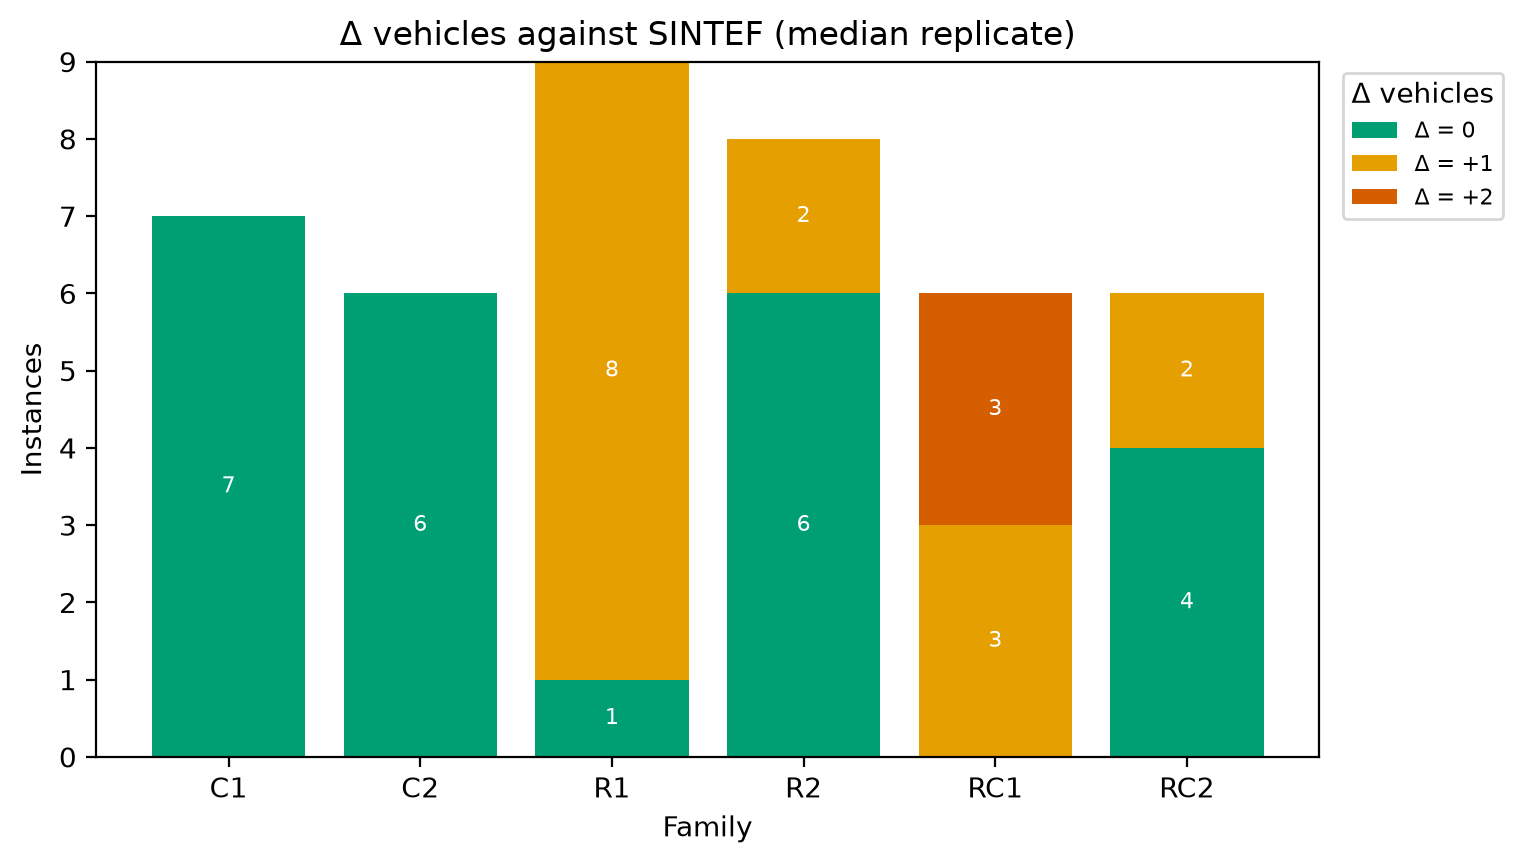

In [4]:
display(eda.localize_columns(final_eval.delta_distribution(inst, LANG), LANG))
display(eda.localize_columns(final_eval.delta_instances(inst, 2), LANG))

viz_final.plot_delta_distribution(inst, LANG)
plt.show()

### Insight

Across the 42 instances, 24 achieve Δ = 0, 15 require +1 vehicle and 3 require +2 (RC101, RC102 and RC105), with zero cases below SINTEF or at +3 or higher. Every one of the 13 C instances reaches Δ = 0; R1 splits into 1 at 0 and 8 at +1; R2 into 6 at 0 and 2 at +1; RC1 into 3 at +1 and 3 at +2; and RC2 into 4 at 0 and 2 at +1. Hence the 0.50 mean Δ stems from widespread +1 differences and three +2 instances in R1 and RC1, keeping in mind that one extra vehicle carries different operational weight across fleets ranging from 2 to 19 vehicles. Section 5 examines distances under equal fleets.

## 5. Instances whose fleet equals the reference

This section profiles the 24 equal-fleet instances, counting exact two-decimal reference matches (within 0.005), positive gaps, median and maximum gaps, and plotting gaps coloured by family.

,Scope,No. of instances,Instances with fleet equal to reference,Reproduce the distance to two decimals,"Equal fleet, distance above","Median gap, equal fleet (%)",Maximum gap (%)
0,Overall,42,24,10,14,3.4,7.92
1,C1,7,7,5,2,0.0,7.92
2,C2,6,6,5,1,0.0,3.6
3,R1,9,1,0,1,0.52,0.52
4,R2,8,6,0,6,5.02,7.83
5,RC1,6,0,0,0,-,-
6,RC2,6,4,0,4,4.63,5.67


,Instance,Family,SINTEF vehicles,SINTEF distance,Vehicles,Distance,Distance gap (%),Reproduces the distance (to two decimals)
0,C101,C1,10,828.94,10,828.94,0.00,Yes
1,C102,C1,10,828.94,10,828.94,0.00,Yes
2,C104,C1,10,824.78,10,888.28,7.70,No
3,C105,C1,10,828.94,10,828.94,0.00,Yes
4,C107,C1,10,828.94,10,828.94,0.00,Yes
5,C108,C1,10,828.94,10,828.94,0.00,Yes
6,C109,C1,10,828.94,10,894.60,7.92,No
7,C201,C2,3,591.56,3,591.56,0.00,Yes
8,C202,C2,3,591.56,3,591.56,0.00,Yes
9,C204,C2,3,590.60,3,611.88,3.60,No


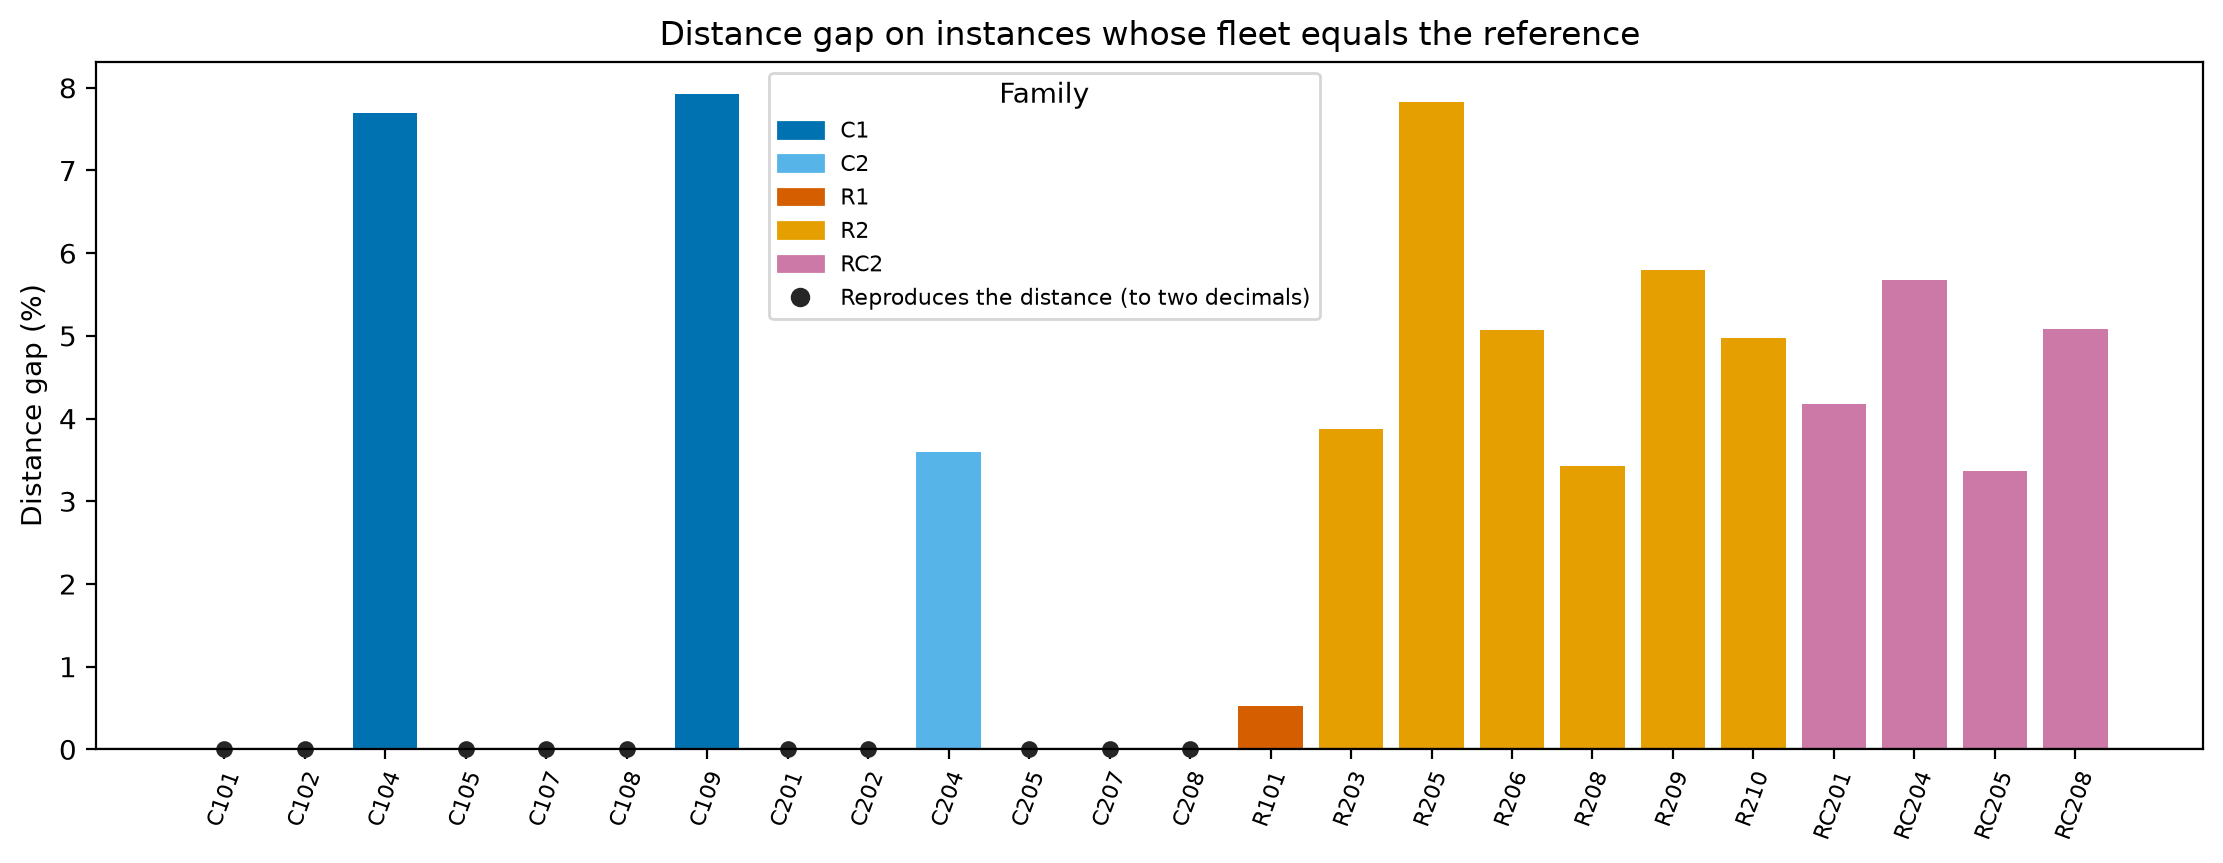

In [5]:
display(eda.localize_columns(final_eval.reproduction_summary(inst, LANG), LANG))
display(eda.localize_columns(final_eval.fleet_equal_table(inst, LANG), LANG))

viz_final.plot_gap_fleet_equal(inst, LANG)
plt.show()

### Insight

Among the 24 equal-fleet instances, 10 match SINTEF distance to two decimals, all within C families (5 of 7 in C1 and 5 of 6 in C2), while the remaining 3 C instances sit above reference (C104 at 7.70%, C109 at 7.92% and C204 at 3.60%). None of the R or RC cases match reference distances: R101 posts 0.52% and the 10 series-2 instances (6 in R2 and 4 in RC2) span from 3.36% (RC205) to 7.83% (R205), setting the overall median gap at 3.40% and maximum at 7.92%. Across the remaining 18 instances with larger fleets, shorter distances do not represent hierarchical gains. Section 6 measures replicate variability.

## 6. Variability across the 5 replicates

The summary measures how many instances vary in fleet count or distance across the 5 replicates (percentage range relative to the minimum feasible distance), listing every instance with non-zero distance spread.

In [6]:
display(eda.localize_columns(final_eval.variability_table(inst, LANG), LANG))
display(eda.localize_columns(final_eval.varying_instances(inst), LANG))

,Scope,No. of instances,Instances with varying fleet,Largest fleet range,Instances with varying distance,Median distance range (%),Maximum distance range (%)
0,Overall,42,0,0,6,0.00,3.21
1,C1,7,0,0,0,0.00,0.00
2,C2,6,0,0,0,0.00,0.00
3,R1,9,0,0,0,0.00,0.00
4,R2,8,0,0,4,0.37,3.21
5,RC1,6,0,0,0,0.00,0.00
6,RC2,6,0,0,2,0.00,0.79


,Instance,Family,Vehicles,Minimum distance,Distance,Maximum distance,Range (%)
0,R203,R2,3,974.38,975.82,1005.65,3.21
1,R209,R2,3,934.08,961.85,961.85,2.97
2,R211,R2,3,826.83,837.54,837.54,1.30
3,RC205,RC2,4,1330.76,1341.31,1341.31,0.79
4,R206,R2,3,945.12,952.09,952.09,0.74
5,RC204,RC2,3,841.21,843.71,843.71,0.30


### Insight

Fleet size stayed invariant across all 5 replicates on every single one of the 42 instances (maximum range zero). Distance varied on just 6 series-2 instances: R203 (3.21%), R209 (2.97%), R211 (1.30%), R206 (0.74%), RC205 (0.79%) and RC204 (0.30%), keeping overall median spread at 0.00% and zero variance in C1, C2, R1 and RC1. Whereas 30 s development runs exhibited ±1 vehicle swings (`reports/sensibilidade-tempo-e-janelas.md`), the 120 s evaluation runs on an idle machine held fleets constant across all 29 R and RC instances, although concurrent shifts in budget, sample and workload prevent attributing stability to a single cause. Section 7 compares OR-Tools against the baselines.

## 7. Baselines against OR-Tools

The tables compare the OR-Tools median replicate against deterministic runs of deadline-first greedy and time-oriented nearest neighbour overall and by family.

In [7]:
display(eda.localize_columns(final_eval.method_comparison(rows, LANG), LANG))
display(eda.localize_columns(final_eval.method_by_family(rows, LANG), LANG))

,Method,No. of instances,Feasible,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Beats the reference
0,OR-Tools,42,42,0.50,24,3.4,0
1,Nearest neighbour with time windows,42,42,1.36,12,71.59,0
2,Deadline-first greedy,42,42,3.98,2,94.83,0


,Method,Overall,C1,C2,R1,R2,RC1,RC2
0,OR-Tools,0.50,0.00,0.00,0.89,0.25,1.50,0.33
1,Nearest neighbour with time windows,1.36,0.29,0.33,2.78,0.88,2.83,0.67
2,Deadline-first greedy,3.98,1.43,1.50,6.56,3.00,7.33,3.50


### Insight

OR-Tools leads in every family with mean Δ 0.50 and 24 equal-fleet matches, ahead of nearest neighbour (1.36 and 12 matches) and deadline-first greedy (3.98 and 2 matches). Gaps widen in time-constrained families: in R1 mean Δ equals 0.89 versus 2.78 and 6.56, and in RC1 1.50 versus 2.83 and 7.33, whereas in C families nearest neighbour approaches closely (0.29 in C1 and 0.33 in C2 against 0.00 for OR-Tools). Equal-fleet median distance gaps stand at 3.40% for OR-Tools against 71.59% (nearest neighbour) and 94.83% (greedy) over distinct matched subsets (24, 12 and 2 instances), showing clear improvement over simple constructive heuristics without claiming state-of-the-art optimality. Section 8 compares evaluation against development behaviour.

## 8. Consistency with development

To check descriptive consistency between subsets at the shared 120 s budget, single-run development results from notebook 04 (14 instances) appear next to evaluation median replicates (42 instances) overall and by family, without hypothesis testing.

In [8]:
time_df = results.load_time_sensitivity(R["time_sensitivity"], split)
budget = cfg.evaluation.time_limit_s

display(eda.localize_columns(final_eval.dev_vs_eval(time_df, inst, budget, LANG), LANG))
display(eda.localize_columns(final_eval.dev_vs_eval_by_family(time_df, inst, budget, LANG), LANG))

,Set,No. of instances,Runs per instance,Mean Δ vehicles,Fleet equal to the reference,"Median gap, equal fleet (%)"
0,Development,14,1,0.64,7 / 14,1.74
1,Evaluation,42,5,0.50,24 / 42,3.4


,Family,Development · No. of instances,Development · Mean Δ vehicles,Development · Instances with fleet equal to reference,Evaluation · No. of instances,Evaluation · Mean Δ vehicles,Evaluation · Instances with fleet equal to reference
0,C1,2,0.00,2,7,0.00,7
1,C2,2,0.00,2,6,0.00,6
2,R1,3,1.33,0,9,0.89,1
3,R2,3,0.67,1,8,0.25,6
4,RC1,2,1.50,0,6,1.50,0
5,RC2,2,0.00,2,6,0.33,4


### Insight

At 120 s, development (14 instances) recorded mean Δ 0.64 with 7 of 14 equal fleets (1.74% median gap), compared with 0.50 and 24 of 42 (3.40% median gap) in evaluation. Family patterns align broadly: C families hold Δ 0.00 with 100% fleet matches in both sets; RC1 holds Δ 1.50 with zero matches in both; R1 reads 1.33 versus 0.89; R2 reads 0.67 versus 0.25; and RC2 reads 0.00 versus 0.33. Evaluation fleet behaviour matches development broadly without claiming superiority across disjoint samples and uncomparable equal-fleet subsets (7 versus 24 cases). Section 9 visualises two representative route plans.

## 9. Routes of the median replicate

The route maps plot the median replicate for C101 (the first C instance matching SINTEF distance to two decimals) and RC101 (the first RC1 instance with the family's maximum Δ), marking the depot in red and showing verifier metrics alongside SINTEF targets.

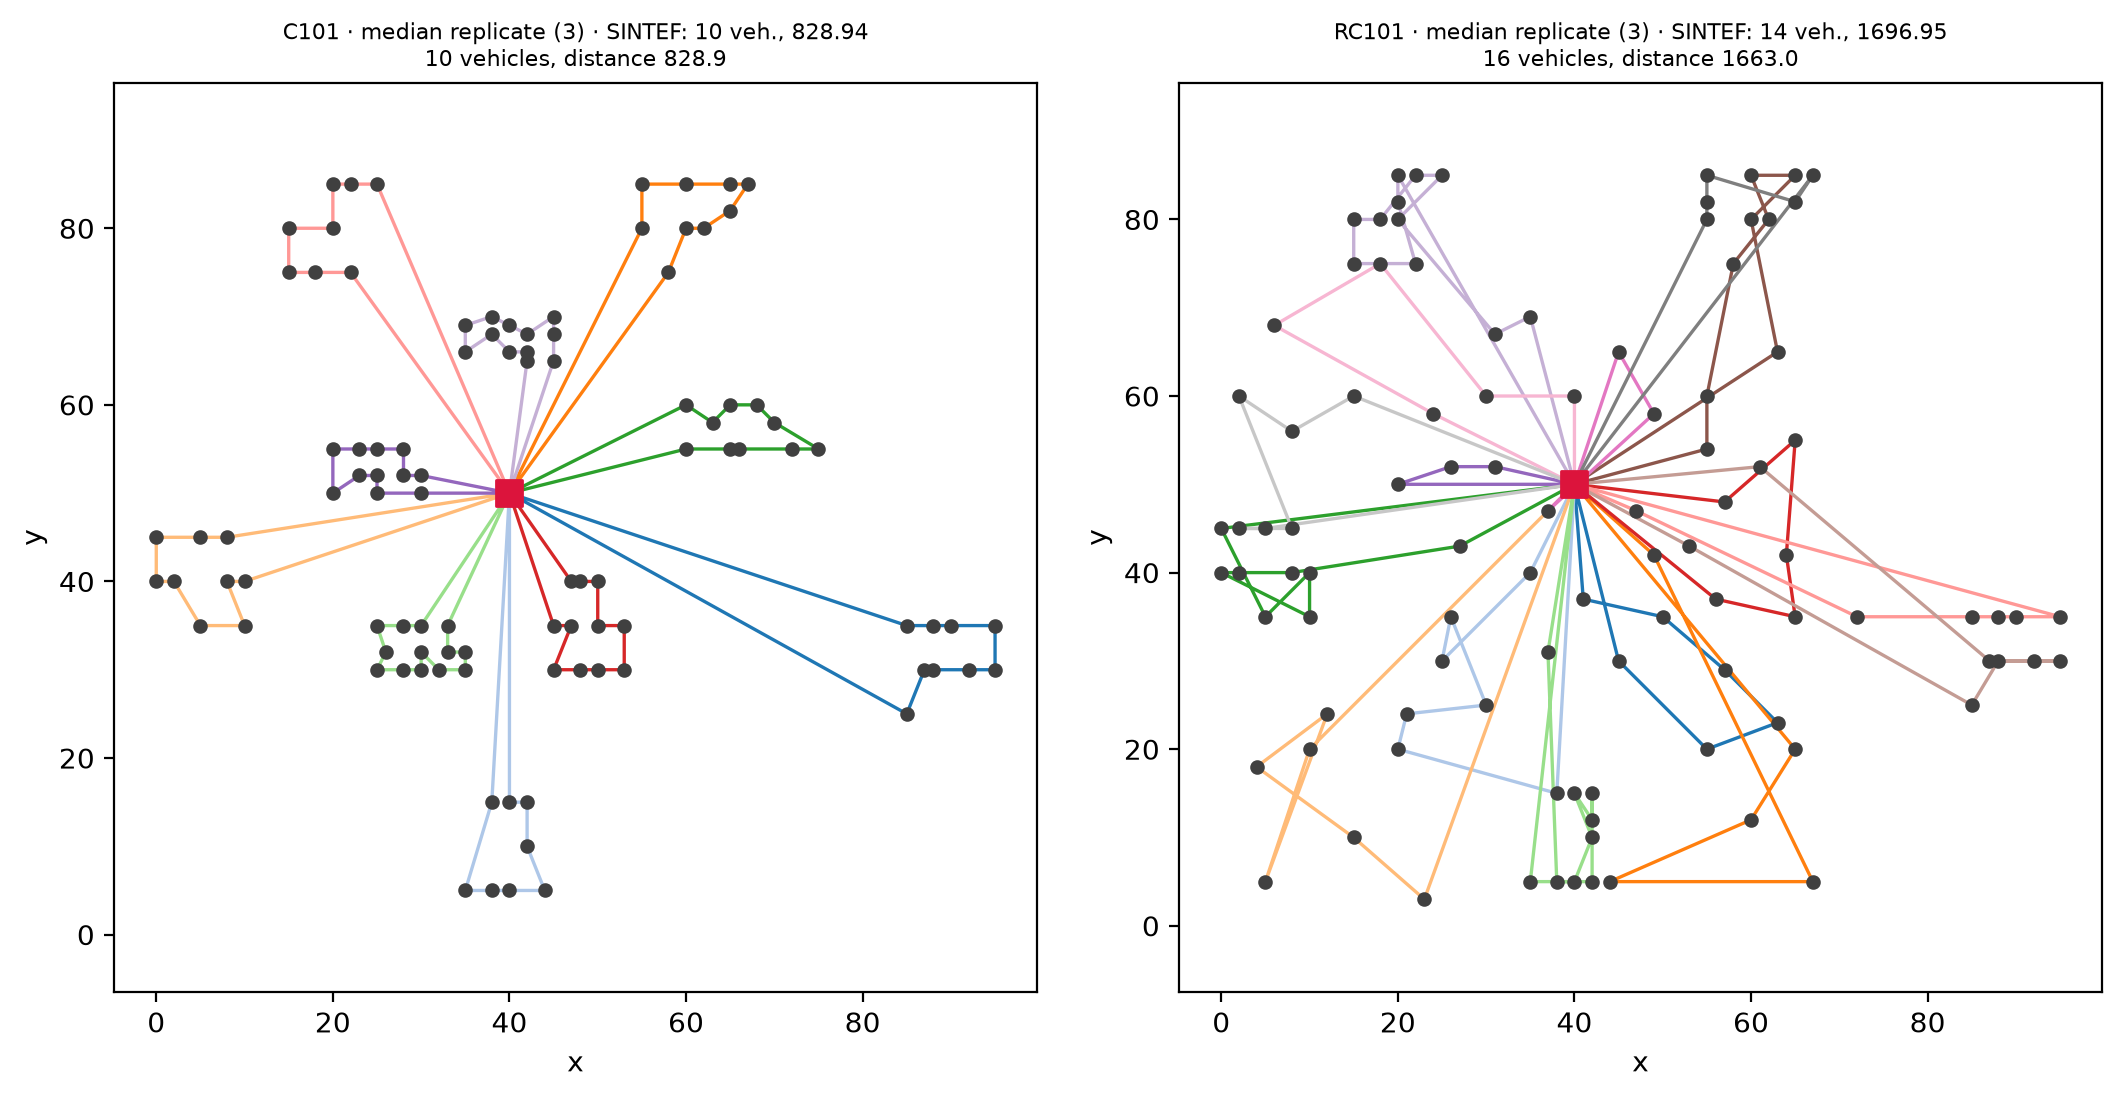

In [9]:
names = final_eval.pick_map_instances(inst)
eval_instances = results.load_eval_instances(P["sintef_zip"], split, names)

viz_results.plot_route_panels(final_eval.median_panels(names, eval_instances, rows, inst, LANG), LANG)
plt.show()

### Insight

On C101 (median replicate 3), the solution uses 10 vehicles and distance 828.9, matching SINTEF (10 vehicles and 828.94) via compact routes over neighbouring clusters with minimal crossings. On RC101 (median replicate 3), it uses 16 vehicles and distance 1663.0 against 14 vehicles and 1696.95 for SINTEF, achieving shorter distance at the cost of 2 extra vehicles through long crossing legs and small fragmented routes caused by mixed clustered and random customers. This qualitative map inspects two rule-selected cases without explaining the structural cause of RC101's extra fleet. Section 10 evaluates route durations derived from frozen schedules.

## 10. Times of the frozen routes

To quantify waiting time and total route duration, schedules were derived post hoc from frozen routes via `scripts/derive_eval_time_metrics.py` without running any solver or modifying frozen artefacts (Toth & Vigo, 2014). Each instance uses the median replicate (OR-Tools) or single run (baselines) under two departure rules: simultaneous start at time zero and optimal departure adjusted via forward time slack (Savelsbergh, 1992). Because SINTEF publishes no durations, no external comparison applies here; three tables present overall medians by method, family breakdowns for OR-Tools and per-instance baseline ratios relative to OR-Tools.

,Method,No. of instances,Distance (median),"Duration, depart at 0 (median)","Waiting, depart at 0 (median)","Duration, optimal departure (median)","Waiting, optimal departure (median)",Last return (median),"Waiting / duration, depart at 0 (%)","Waiting / duration, optimal departure (%)"
0,OR-Tools,42,979.8,2894.2,269.3,2590.8,43.1,921.4,10.3,1.6
1,Deadline-first greedy,42,2696.4,5364.6,787.0,4146.2,16.3,977.8,13.9,0.4
2,Nearest neighbour with time windows,42,1608.7,3608.1,382.8,3021.6,0.3,968.9,10.5,0.0


,Family,No. of instances,Distance (median),"Duration, depart at 0 (median)","Waiting, depart at 0 (median)","Duration, optimal departure (median)","Waiting, optimal departure (median)",Last return (median),"Waiting / duration, depart at 0 (%)","Waiting / duration, optimal departure (%)"
0,C1,7,828.9,9828.9,0.0,9828.9,0.0,1234.8,0.0,0.0
1,C2,6,590.2,9626.0,36.1,9590.2,0.0,3386.9,0.4,0.0
2,R1,9,1227.7,2470.6,213.3,2300.6,54.2,228.4,9.2,2.2
3,R2,8,957.0,2526.3,545.4,2258.0,245.8,942.4,22.4,10.9
4,RC1,6,1432.5,2738.3,305.8,2496.0,41.3,237.3,11.0,1.6
5,RC2,6,1142.5,3126.9,874.5,2684.0,558.8,921.4,28.8,20.7


,Family,Method,No. of instances,Distance (OR-Tools = 100%),"Duration, optimal departure (OR-Tools = 100%)"
0,Overall,Deadline-first greedy,42,258.6,144.3
1,Overall,Nearest neighbour with time windows,42,152.4,113.3
2,C1,Deadline-first greedy,7,261.9,115.1
3,C1,Nearest neighbour with time windows,7,154.9,105.0
4,C2,Deadline-first greedy,6,272.7,120.9
5,C2,Nearest neighbour with time windows,6,152.4,103.2
6,R1,Deadline-first greedy,9,181.4,143.7
7,R1,Nearest neighbour with time windows,9,133.9,115.9
8,R2,Deadline-first greedy,8,307.0,182.2
9,R2,Nearest neighbour with time windows,8,177.3,120.5


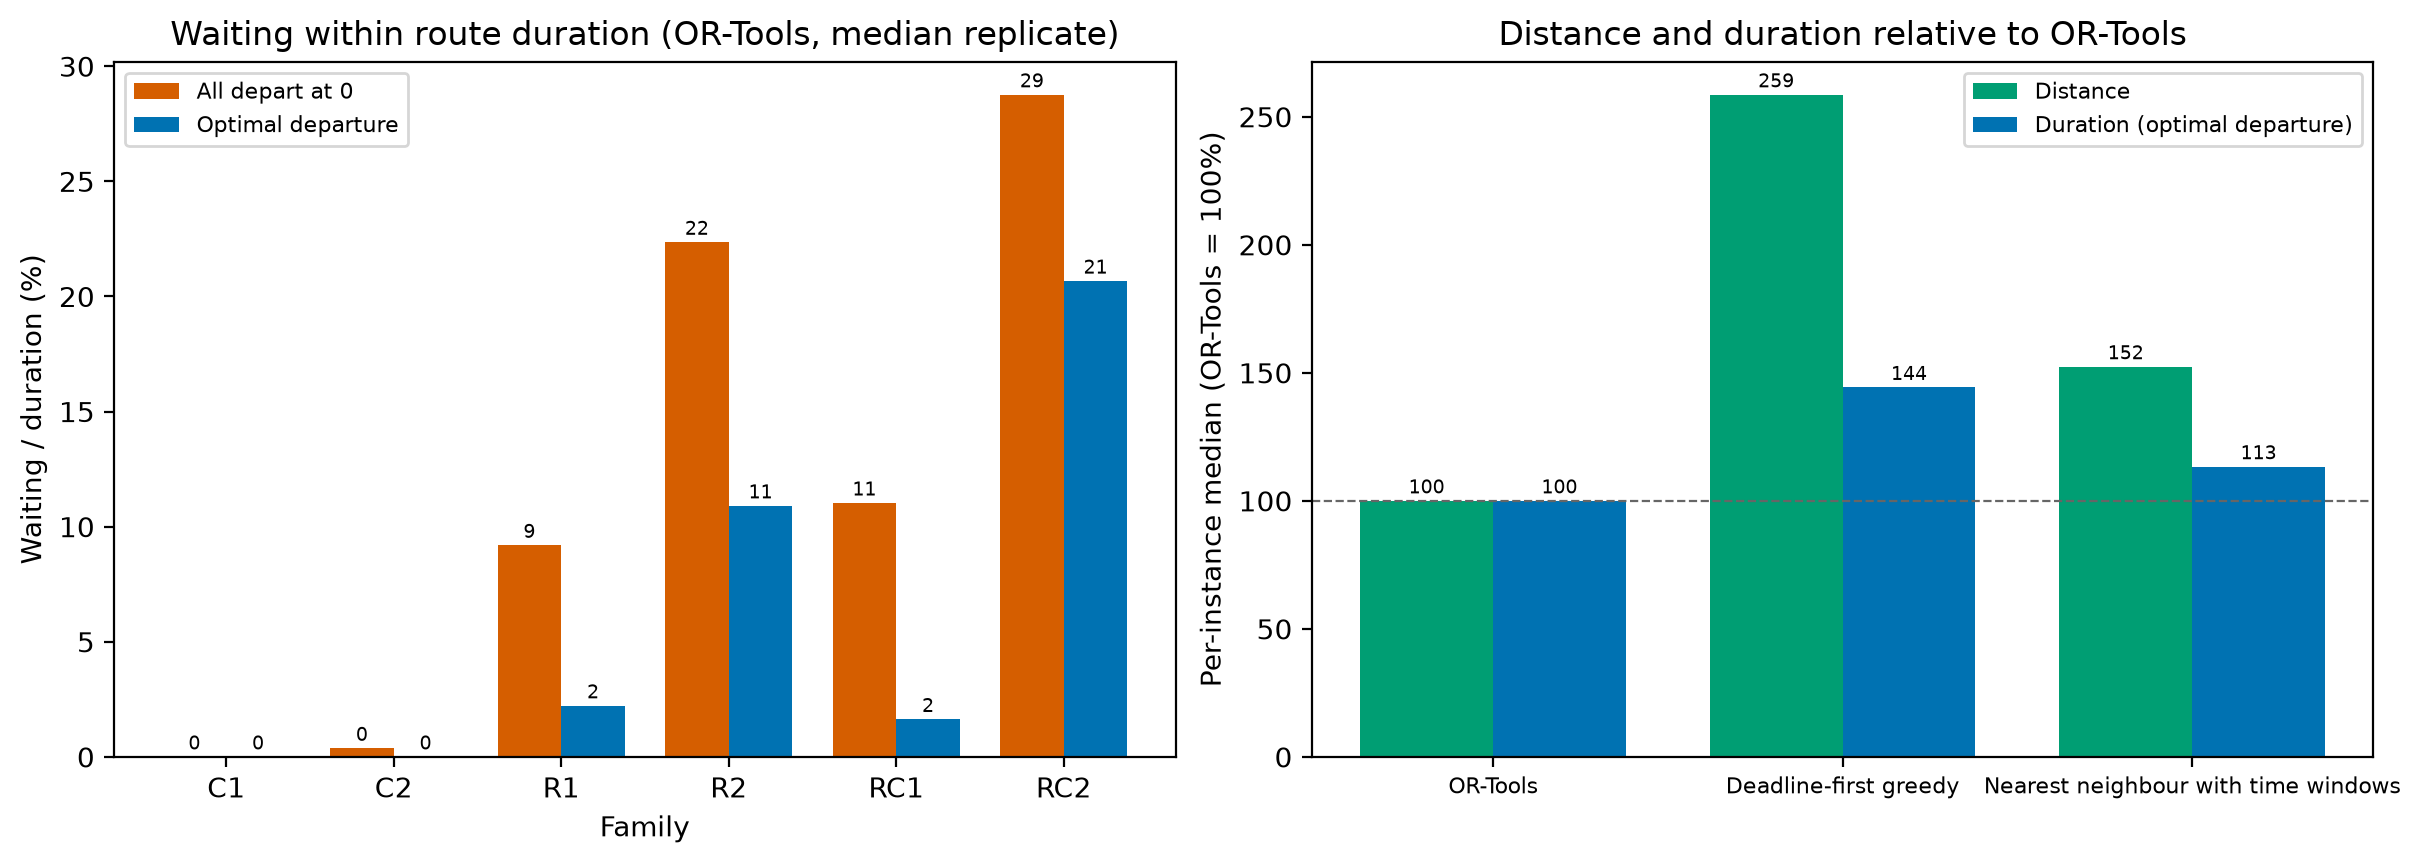

In [10]:
tm = results.load_eval_time_metrics(R["eval_time_metrics"], split)
tagg = final_eval.time_aggregate(final_eval.time_representatives(tm))

display(eda.localize_columns(final_eval.time_method_table(tagg, LANG), LANG))
display(eda.localize_columns(final_eval.time_family_table(tagg), LANG))
display(eda.localize_columns(final_eval.time_ratio_table(tagg, LANG), LANG))

viz_final.plot_time_metrics(tagg, LANG)
plt.show()

### Insight

With OR-Tools median replicates, per-instance medians stand at 979.8 distance, 2894.2 duration and 269.3 waiting under departure at zero (10.3% waiting), falling to 2590.8 duration and 43.1 waiting under optimal departure (1.6% waiting), with last depot return at 921.4. Under optimal departure, baselines record median durations of 4146.2 (greedy) and 3021.6 (nearest neighbour), returning at 977.8 and 968.9. Paired per instance against OR-Tools, greedy takes 258.6% distance and 144.3% duration, while nearest neighbour takes 152.4% and 113.3%.

Duration advantages are narrower than distance gaps because fixed service dominates C instances (for instance 9000 service on C1 for 828.9 distance) and baselines incur less waiting (16.3 and 0.3 versus 43.1 under optimal departure), yet OR-Tools stays ahead in duration across every family (103.2% to 182.2%). Waiting is negligible in C families (0.0% and 0.4%) and substantial in series 2 (22.4% in R2 and 28.8% in RC2 at departure 0, dropping to 10.9% and 20.7% under optimal departure due solely to unavoidable inter-customer slack). Because the solver optimises fleet and distance rather than time and medians mix distinct service scales, these durations serve purely as descriptive metrics.

## 11. Post-hoc v2 re-evaluation

This section is strictly post hoc because all 42 evaluation instances had already been examined in sections 1 through 10. Following the external audit and Phase B diagnostics (notebook 04, section 9), the v2 configuration ran on the same 42 instances under `reports/protocolo-fase-d.md`, keeping v1 intact as the primary original outcome without replacement or selective reporting.

The v2 configuration retains 120 s, 5 replicates, 8 workers and v1 baselines while changing both integer scale to 10 000 (versus 100 in v1) and relative fixed cost to k = 10 (`10 × D_ub` per vehicle, corresponding to 49.9%–66.2% of v1's `10^5` distance-unit fixed cost). Changing both parameters simultaneously compares two distinct configurations rather than isolating integer scale, treating equal-fleet distance shifts under 0.5% as inter-run noise.

The following tables verify v2 run integrity, report main v2 outcomes against SINTEF and display v1 beside v2 (`comparison_by_instance.csv` and recomputed aggregates matching `comparison_aggregate.csv`).

In [11]:
rows_v2 = results.load_evaluation(R["evaluation_v2"], split)
inst_v2 = evaluation.instance_table(rows_v2)
by_instance = results.load_evaluation_comparison(R["evaluation_v2_comparison"], split)
_, aggregate = evaluation.compare_versions(rows, rows_v2)

display(eda.localize_columns(final_eval.integrity_table(rows_v2, split, LANG), LANG))
display(eda.localize_columns(final_eval.main_table(rows_v2, LANG), LANG))
display(eda.localize_columns(final_eval.version_aggregate_table(aggregate, LANG), LANG))

,Indicator,Value
0,Cells in the file (total),210
1,OR-Tools cells (instances × replicates),210
2,Baseline cells,0
3,Distinct instances,42
4,Evaluation instances in the split,42
5,Development instances in the results,0
6,OR-Tools replicates per instance,5
7,Cells feasible in the verifier,210 / 210
8,OR-Tools runs with success status,210 / 210
9,Mean time per OR-Tools run (s),120.0


,Result,Scope,No. of instances,Mean Δ vehicles,Instances with fleet equal to reference,"Median gap, equal fleet (%)",Beats the reference
0,Median replicate (main result),Overall,42,0.48,25,2.23,0
1,Median replicate (main result),C1,7,0.00,7,0.0,0
2,Median replicate (main result),C2,6,0.00,6,0.0,0
3,Median replicate (main result),R1,9,0.89,1,0.52,0
4,Median replicate (main result),R2,8,0.25,6,4.95,0
5,Median replicate (main result),RC1,6,1.50,0,-,0
6,Median replicate (main result),RC2,6,0.17,5,6.29,0


,Scope,No. of instances,Mean Δ vehicles (v1),Mean Δ vehicles (v2),Fleet equal to SINTEF (v1),Fleet equal to SINTEF (v2),"Median gap, equal fleet (%, v1)","Median gap, equal fleet (%, v2)",Distance within noise (< 0.5%)
0,Overall,42,0.50,0.48,24,25,3.4,2.23,18
1,C1,7,0.00,0.00,7,7,0.0,0.0,6
2,C2,6,0.00,0.00,6,6,0.0,0.0,6
3,R1,9,0.89,0.89,1,1,0.52,0.52,3
4,R2,8,0.25,0.25,6,6,5.02,4.95,1
5,RC1,6,1.50,1.50,0,0,-,-,2
6,RC2,6,0.33,0.17,4,5,4.63,6.29,0


### Insight

The v2 run complied with the Phase D protocol across 210 fully feasible OR-Tools cells at 120.0 s (120.00 to 120.04 s) confined to the 42 evaluation instances. On the median replicate, v2 posted mean Δ 0.48 (versus 0.50 in v1), matching SINTEF fleets on 25 instances (versus 24) with a 2.23% median gap (versus 3.40%). C1, C2, R1 and RC1 stayed unchanged; R2 kept Δ 0.25 and 6 matches (median gap shifting from 5.02% to 4.95%), whereas RC2 moved from Δ 0.33 to 0.17 and from 4 to 5 matches (shifting its median gap from 4.63% to 6.29% due to the expanded subset). Overall, 18 of 42 instances lay within the 0.5% noise band. Because this comparison is post hoc across changing equal-fleet subsets, it conflates integer scale and fixed-cost magnitude, which are compared directly next.

The table contrasts fixed vehicle costs between v1 (`10^5` constant distance units) and v2 (`10 × D_ub`, sum of round-trip depot–customer distances) across all 42 evaluation instances overall and by family.

In [12]:
fixed_cost = final_eval.evaluation_fixed_cost_table(
    P["sintef_zip"], split, rows_v2["instance"].unique(), max(cfg.v2.scales), cfg.v2.k_default
)
display(eda.localize_columns(final_eval.fixed_cost_ratio_summary(fixed_cost, LANG), LANG))


,Scope,No. of instances,v1 fixed cost (distance units),"v2 / v1 fixed cost, minimum (%)","v2 / v1 fixed cost, median (%)","v2 / v1 fixed cost, maximum (%)",Instance of the minimum,Instance of the maximum
0,Overall,42,100000.0,49.9,57.7,66.2,R101,RC101
1,C1,7,100000.0,57.7,57.7,57.7,C101,C101
2,C2,6,100000.0,59.4,59.4,59.4,C201,C201
3,R1,9,100000.0,49.9,49.9,49.9,R101,R101
4,R2,8,100000.0,49.9,49.9,49.9,R203,R203
5,RC1,6,100000.0,66.2,66.2,66.2,RC101,RC101
6,RC2,6,100000.0,66.2,66.2,66.2,RC201,RC201


### Insight

Whereas v1 applies a flat 100 000 distance-unit fixed cost (roughly 15 to 20 times `D_ub`), v2's `10 × D_ub` depends on the instance and is smaller: ranging from 49.9% of v1 at minimum (R1 and R2, such as R101), 57.7% at the median (57.7% in C1, 59.4% in C2) up to 66.2% at maximum (RC1 and RC2, such as RC101). Consequently, the initial statement describing k = 10 as equivalent in magnitude to v1 proved incorrect: v2 differs from v1 in both integer scale and fixed-cost magnitude, attributing RC207's change to the combined v2 configuration. Controlled development experiments isolated scale in B1 and observed invariant fleets across k in B2, yet no evaluation experiment separated both factors on held-out instances. Instance-by-instance differences follow.

The tables and plot compare v2 against v1 per instance, detailing fleet shifts and equal-fleet distance changes of at least 0.5% alongside the highlighted noise band.

,Item,Count,Detail
0,Instances compared,42,
1,Smaller fleet in v2,1,RC207
2,Larger fleet in v2,0,
3,Equal fleet in both versions,41,
4,Distance within noise (equal fleet),18,|Δ| < 0.5%
5,"Shorter distance in v2, beyond noise",11,Δ ≤ −0.5%
6,"Longer distance in v2, beyond noise",12,Δ ≥ +0.5%
7,Smallest distance difference,-,-4.3%
8,Largest distance difference,-,+2.1%


,Instance,Family,SINTEF vehicles,Vehicles (v1),Vehicles (v2),Distance (v1),Distance (v2),Distance v2 against v1 (%),"v2 gap to SINTEF (%, equal fleet)"
0,RC207,RC2,3,4,3,1039.1,1178.6,-,11.07
1,RC204,RC2,3,3,3,843.7,807.6,-4.28,1.14
2,R109,R1,11,12,12,1227.7,1179.3,-3.95,-
3,RC202,RC2,3,4,4,1245.8,1198.7,-3.79,-
4,C104,C1,10,10,10,888.3,860.7,-3.1,4.36
5,R205,R2,3,3,3,1072.3,1042.8,-2.74,4.87
6,R107,R1,10,11,11,1107.3,1092.8,-1.32,-
7,RC107,RC1,11,12,12,1279.3,1264.4,-1.16,-
8,R209,R2,3,3,3,961.9,950.8,-1.15,4.58
9,RC205,RC2,4,4,4,1341.3,1326.6,-1.1,2.23


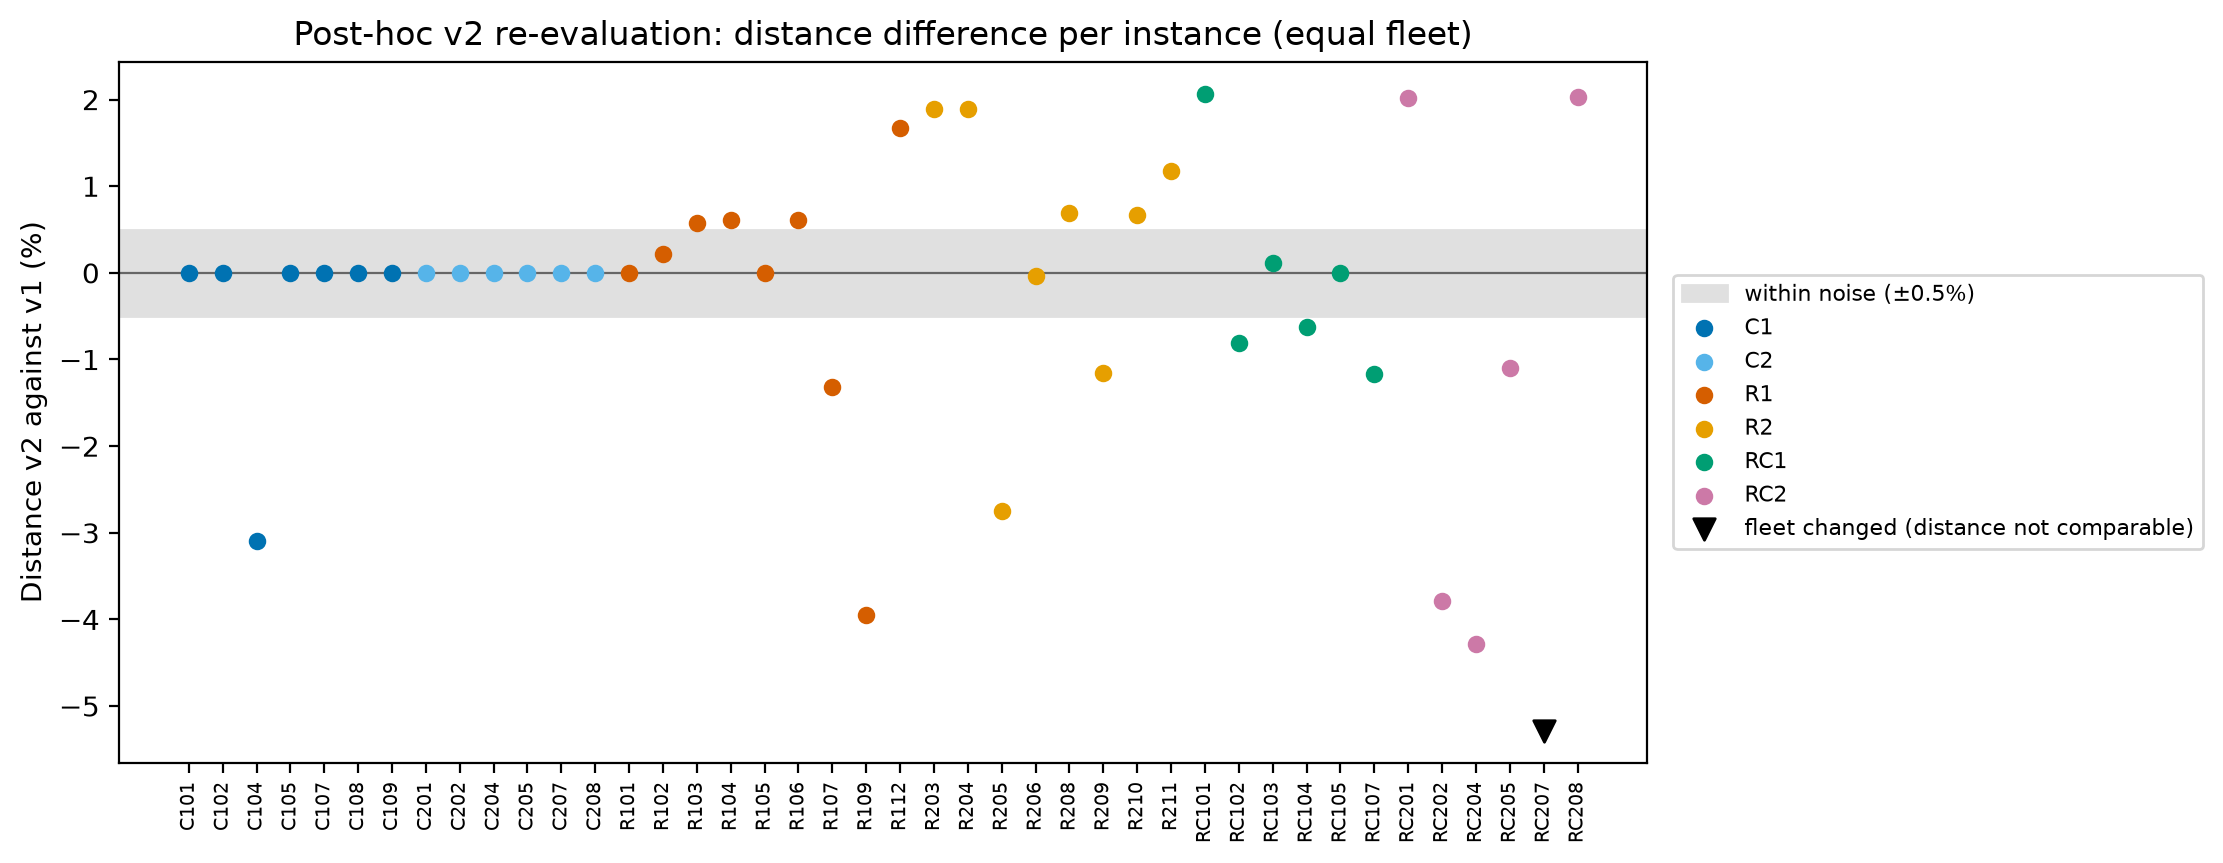

In [13]:
display(eda.localize_columns(final_eval.version_distance_summary(by_instance, LANG), LANG))
display(eda.localize_columns(final_eval.version_changes(by_instance, LANG), LANG))

viz_final.plot_version_comparison(by_instance, LANG)
plt.show()

### Insight

Fleet size changed on a single instance: RC207 dropped from 4 to 3 vehicles in v2, matching SINTEF as distance moved from 1039.1 to 1178.6 (11.07% gap to reference). The pre-registered expectation of tight-window fleet gains such as R106 failed to materialise, with R106 remaining at 13 vehicles in both versions (+0.61% distance). Across the 41 unchanged-fleet instances, 18 moved less than 0.5%, 11 shortened beyond noise (down to −4.28% on RC204) and 12 lengthened (up to +2.07% on RC101), showing symmetric two-way scatter (−4.3% to +2.1%) with zero systematic bias. Thus, the median gap shift from 3.40% to 2.23% reflects bilateral fluctuations and RC207's entry rather than systematic distance improvement. Section stability across v2 replicates is checked next.

The table repeats the replicate-spread check of section 6 across the 5 replicates of v2, listing every instance with varying distance.

In [14]:
display(eda.localize_columns(final_eval.variability_table(inst_v2, LANG), LANG))
display(eda.localize_columns(final_eval.varying_instances(inst_v2), LANG))

,Scope,No. of instances,Instances with varying fleet,Largest fleet range,Instances with varying distance,Median distance range (%),Maximum distance range (%)
0,Overall,42,0,0,4,0.0,3.02
1,C1,7,0,0,0,0.0,0.00
2,C2,6,0,0,0,0.0,0.00
3,R1,9,0,0,3,0.0,0.74
4,R2,8,0,0,0,0.0,0.00
5,RC1,6,0,0,0,0.0,0.00
6,RC2,6,0,0,1,0.0,3.02


,Instance,Family,Vehicles,Minimum distance,Distance,Maximum distance,Range (%)
0,RC208,RC2,3,861.82,887.87,887.87,3.02
1,R112,R1,10,992.86,1000.22,1000.22,0.74
2,R106,R1,13,1269.41,1269.41,1271.23,0.14
3,R107,R1,11,1091.67,1092.76,1092.76,0.10


### Insight

Consistent with v1, v2 fleet counts never varied across the 5 replicates on any of the 42 instances. Distance varied on only 4 instances (RC208 at 3.02%, R112 at 0.74%, R106 at 0.14% and R107 at 0.10%) versus 6 in v1, holding overall median spread at 0.00% and zero spread in C, R2 and RC1. Consequently, differences such as C104's −3.1% between v1 and v2 exceed internal replicate noise, though the exact causal factor (scale, fixed cost or trajectory) remains unisolated. Overall, scale 10 000 fixes the pruning defect identified on R106 and R110 and v2 matches RC207's fleet, yet aggregate impact stays marginal and leaves v1 conclusions intact.

## 12. Synthesis and limitations

On the 42 held-out evaluation instances under the pre-registered protocol, the frozen v1 configuration achieved 100% feasibility across all 294 cells with a mean Δ of 0.50 extra vehicles against SINTEF, matching fleets on 24 instances and never exceeding +2. Performance stayed closest to reference in C families (equal fleets on all 13 instances, with 10 reproducing reference distances to two decimal places) and series 2 (10 matches in 14 instances, distance gaps 3.4% to 7.8%), while reaching its operational limit on tight-window series 1 (R1 and RC1, where only 1 of 15 matched fleets and all three +2 cases occurred). Fleets stayed stable across replicates in 100% of cases, OR-Tools beat both baselines across every family (mean Δ 0.50 versus 1.36 and 3.98) and results aligned broadly with development runs.

Derived schedule metrics (section 10) showed optimal-departure median route durations of 2590.8 for OR-Tools against 3021.6 (nearest neighbour) and 4146.2 (greedy), with depart-at-zero waiting reaching 22.4% in R2 and 28.8% in RC2 even though duration is not a solver objective. Post-hoc v2 re-evaluation (section 11) lowered RC207 from 4 to 3 vehicles via combined scale 10 000 and relative fixed cost, shifting mean Δ from 0.50 to 0.48 (24 to 25 equal fleets) alongside two-way distance variance (−4.3% to +2.1%), leaving original v1 as the main finding.

These outcomes remain purely descriptive and support neither optimality claims (SINTEF reports heuristic best known solutions under finite solver budgets), causal attribution for extra vehicles in R1 and RC1, generalisation to real-world road operations (Solomon being a synthetic planar benchmark), nor broad superiority over untested configurations; likewise, v2 neither replaces v1 nor isolates scale alone on RC207. As a protocol record, an agent edited notebook 04 during the evaluation run without executing code, causing negligible CPU activity that left all 5-replicate fleet counts invariant while leaving minor distance jitter on the 6 varying instances formally unexcluded.

Notebook 06 next examines business-layer window relaxations on the development instances without SINTEF comparisons, while notebook 07 analyses fixed-plan robustness under delays and operational constraints.

## References

- Barr, R. S., Golden, B. L., Kelly, J. P., Resende, M. G. C., & Stewart, W. R. (1995). Designing and reporting on computational experiments with heuristic methods. *Journal of Heuristics, 1*(1), 9–32.
- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- Clarke, G., & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research, 12*(4), 568–581.
- Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Article 15.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: Minimizing route duration. *ORSA Journal on Computing, 4*(2), 146–154.
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.
- Voudouris, C., & Tsang, E. (1999). Guided local search and its application to the traveling salesman problem. *European Journal of Operational Research, 113*(2), 469–499.